# CTLs across many sites — `plot_range_ctl`

In an amorphous material, or any system with many inequivalent sites, one defect type has a whole distribution of formation energies. `plot_range_ctl` puts every site on one diagram:

- a thin line for each site/cell's lowest-energy envelope,
- a shaded band between the lowest and highest envelope at each Fermi energy,
- a bold line for the overall lowest envelope.

Each site is computed against **its own cell's** bulk energy and VBM. The Fermi axis is then referenced to the **mean VBM** of the cells so all sites share one zero.

> The data in `data/amorphous_defects.csv` are **illustrative only**. They were made by `data/make_example_data.py`, which adds noise to the crystalline HfO$_2$ numbers. They are not real calculations.

In [1]:
import csv
from cp2k_utils.ctl import Cell, Material, load_defects_csv, plot_range_ctl

## 1. Cells and materials

Every calculation cell is a `Cell`, with all energies in **Ha**:

```python
Cell(cell_id, vbm, cbm, bulk, alignment=0.0)
```

- `bulk` is the pristine total energy of that cell.
- `alignment` (optional) is a potential alignment shift added to the band edges.

The cells are grouped into a `Material`:

```python
Material(name, title=None, cells=[...], offset=0.0)
```

`offset` is only used by `plot_multi_mat_ctl`.

Each `Defect` says which cell it belongs to through `cell_id`, and which site through `site_id`. All charge states with the same (`material`, `label`, `cell_id`, `site_id`) are treated as one configuration.

In [2]:
# read the per-cell band edges / bulk energies
cells = {}
with open('data/amorphous_cells.csv') as fh:
    for row in csv.DictReader(fh):
        cells.setdefault(row['material'], []).append(
            Cell(row['cell_id'], float(row['vbm']), float(row['cbm']), float(row['bulk'])))

hfo2 = Material('HfO2', cells=cells['HfO2'])
print(hfo2.display_label, f'mean gap = {hfo2.mean_gap_eV:.2f} eV')
for c in hfo2.cells:
    print(f'  {c.cell_id}: VBM {c.vbm_eV:.3f} eV, CBM {c.cbm_eV:.3f} eV')

HfO$_{2}$ mean gap = 4.07 eV
  a1: VBM 7.823 eV, CBM 11.891 eV
  a2: VBM 7.758 eV, CBM 11.870 eV
  a3: VBM 7.889 eV, CBM 11.921 eV


In [3]:
defects = load_defects_csv('data/amorphous_defects.csv')

# plot_range_ctl takes ONE defect type in ONE material
n_i = [d for d in defects if d.material == 'HfO2' and d.label == 'N_i']
print(len(n_i), 'Defect rows,', len({(d.cell_id, d.site_id) for d in n_i}), 'configurations')

36 Defect rows, 9 configurations


## 2. Plotting

| argument | default | |
|---|---|---|
| `shade` | `True` | fill between the lowest and highest envelope |
| `title` | `None` | plot title |
| `save`, `save_format` | `True`, `'pdf'` | |
| `filename` | `None` | defaults to `'<label> Range CTL Diagram.<save_format>'` |
| `show` | `False` | |

It returns `(fig, ax)`, which you can keep editing with matplotlib.

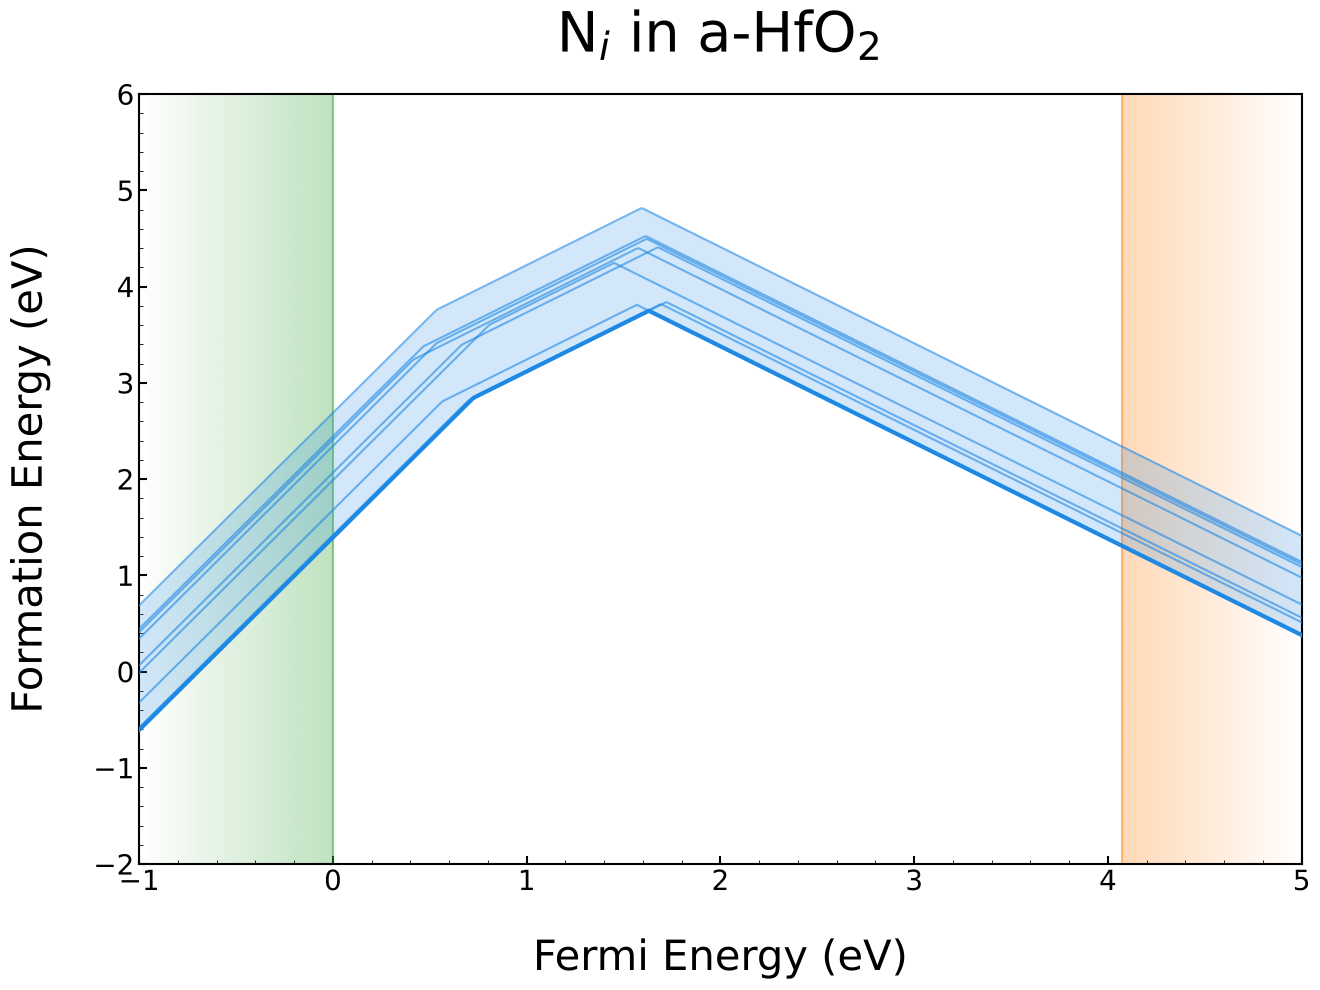

In [4]:
fig, ax = plot_range_ctl(n_i, hfo2, title='N$_i$ in a-HfO$_2$', save=False, show=True)

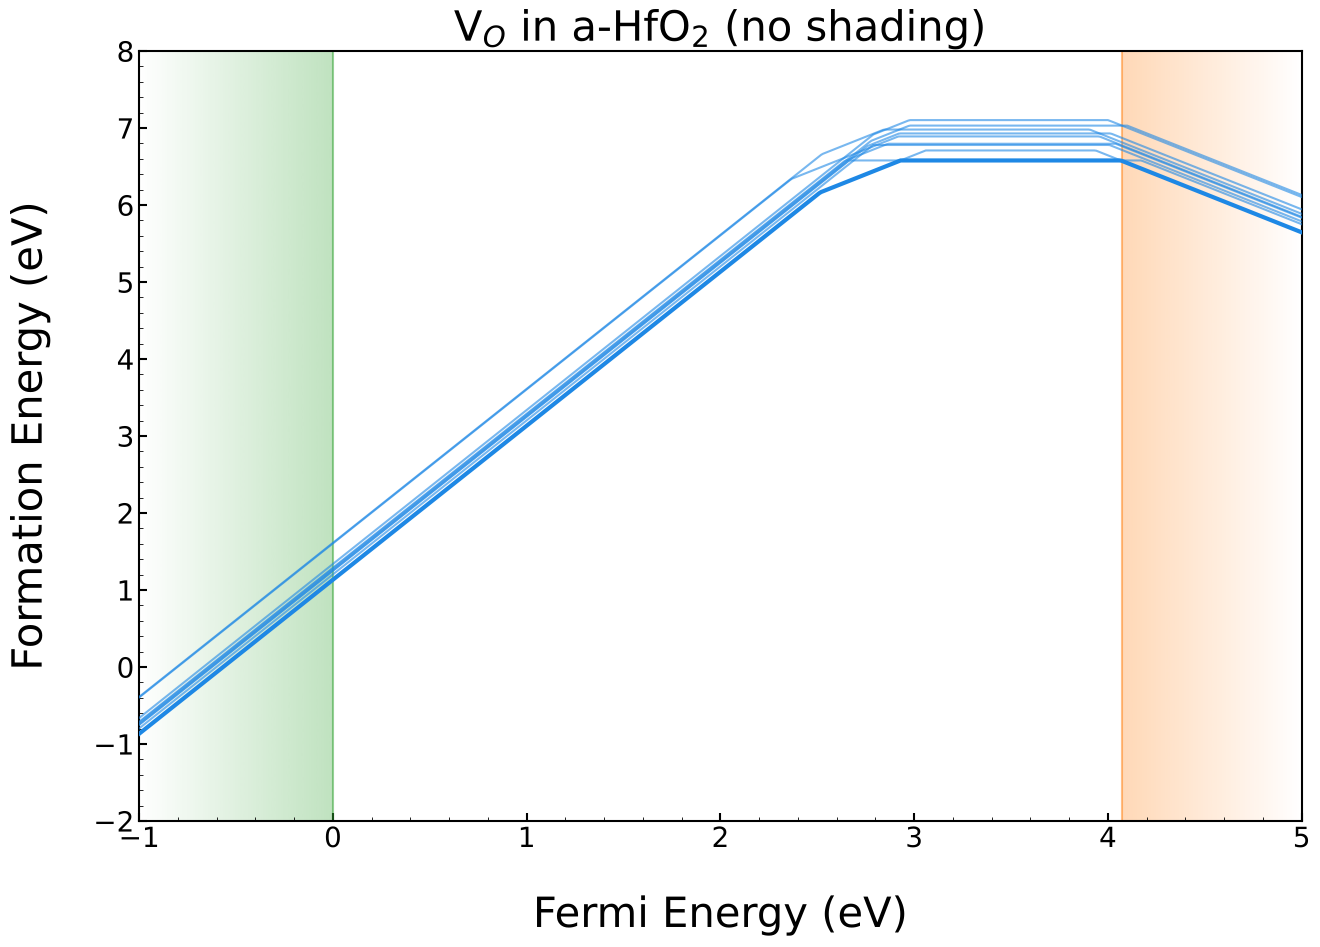

In [5]:
v_o = [d for d in defects if d.material == 'HfO2' and d.label == 'V_O']
fig, ax = plot_range_ctl(v_o, hfo2, shade=False, save=False)
ax.set_title('V$_O$ in a-HfO$_2$ (no shading)', size=30);